## Lab: Market Return Dynamics

AI Disclosure: I used Claude Sonnet AI to help with turning the class code into working code for this lab. The written interpretations are my own. 

We will repeat the weather analysis using the stock market's daily percentage change, recorded in `market_return_pct` in `ff_market_daily.parquet`.

- **2** means the market gained 2% that day.
- **−2** means the market lost 2%.
- **0** means no change.

Use `market_return_pct` as it is. Each row is one trading day, so the next row is the next day the market was open.

**Does today's category help predict the next trading day's category?**


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd 

df = pd.read_parquet('../data/ff_market_daily.parquet')
df['date'] = pd.to_datetime(df['date'])
df = df.sort_values('date').reset_index(drop=True)

print(f"{len(df):,} trading-day observations: "
      f"{df['date'].min():%Y-%m-%d} to {df['date'].max():%Y-%m-%d}")
print(f"Are dates ordered? {df['date'].is_monotonic_increasing}")
df[['date', 'market_return_pct']].head()

26,296 trading-day observations: 1926-07-01 to 2026-07-31
Are dates ordered? True


,date,market_return_pct
0,1926-07-01,0.10
1,1926-07-02,0.46
2,1926-07-06,0.18
3,1926-07-07,0.10
4,1926-07-08,0.23


Here are plots of `market_return_pct`, as a kernel density plot and a time series.

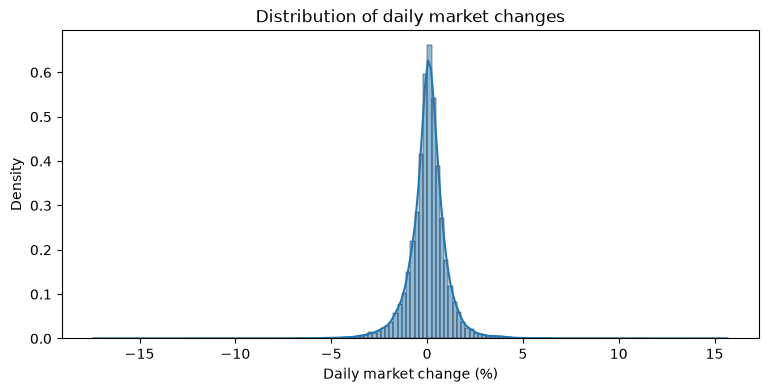

In [2]:
fig, ax = plt.subplots(figsize=(9, 4))
sns.histplot(data=df, x='market_return_pct', bins=150, stat='density', kde=True, ax=ax)
ax.set(xlabel='Daily market change (%)', title='Distribution of daily market changes')
plt.show()

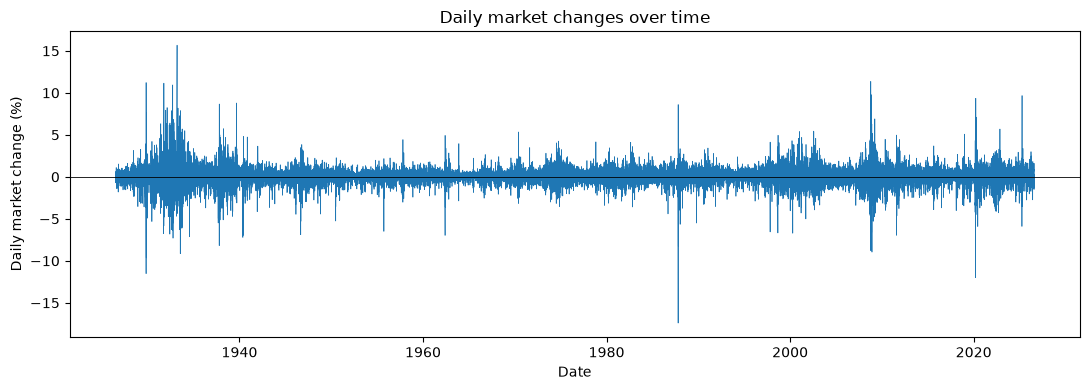

In [3]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(df['date'], df['market_return_pct'], linewidth=0.5)
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel='Date', ylabel='Daily market change (%)',
       title='Daily market changes over time')
fig.tight_layout()
plt.show()

***

### 1. Two States

- Start with two categories: **Up** for values greater than 0, and **Down (and flat)** for values less than or equal to 0. Create variables in your dataframe to capture the current and next value of `market_return_pct`.
- Pair today's category with the next trading day's category. Compute the joint PMF and marginals, and the conditional PMF. 
- Are up transitions more or less common than down transitions? 
- Are you more likely to transition to an Up day from a Down or Up day?

In [4]:
df['y_t'] = np.where(df['market_return_pct'] > 0, 'Up', 'Down/flat')
df['y_tp1'] = df['y_t'].shift(-1)  # next trading day's category (last row has no successor -> NaN)
df['r_tp1'] = df['market_return_pct'].shift(-1)
pairs = df.dropna(subset=['y_tp1'])  # complete pairs only
pd.crosstab(pairs['y_t'], pairs['y_tp1'])

y_tp1,Down/flat,Up
y_t,,
Down/flat,5909,5999
Up,5999,8388


In [5]:
joint2 = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize=True, margins=True)
joint2

y_tp1,Down/flat,Up,All
y_t,,,
Down/flat,0.224720,0.228142,0.452862
Up,0.228142,0.318996,0.547138
All,0.452862,0.547138,1.000000


In [6]:
cond2 = pd.crosstab(pairs['y_t'], pairs['y_tp1'], normalize='index')
cond2

y_tp1,Down/flat,Up
y_t,,
Down/flat,0.496221,0.503779
Up,0.416974,0.583026


**1A:** Up days are more common than down days. About 54.7% of days are Up and 45.3% are Down/flat.

**1B:** You are more likely to get an Up day after an Up day. The chance of Up tomorrow is about 58.3% if today was Up, and about 50.4% if today was Down/flat. So after a Down/flat day it is basically a coin flip, and after an Up day it is a bit more likely to go up again. Both numbers differ from the overall 54.7%, so today does help a little, but not by much.

***

### 2. Binning a Continuous Variable

Now keep the sign and a coarse measure of the size of a daily log return:

| Category | Daily log return (%) |
| --- | --- |
| Large loss | $r \leq -1$ |
| Small loss | $-1 < r \leq -0.1$ |
| Near zero | $-0.1 < r \leq 0.1$ |
| Small gain | $0.1 < r \leq 1$ |
| Large gain | $r > 1$ |

For example, −2 belongs to **Large loss**, 0.05 to **Near zero**, and 0.8 to **Small gain**. These cutoffs are choices for this exercise. Each interval includes its upper endpoint; `-np.inf` and `np.inf` let the outer intervals include any size loss or gain.

- `pd.cut` to group `market_return_pct` into the five categories above. How many days fall into each of the five bins? Which are the most or least common?
- Compute the joint PMF and marginals. Which transitions are most likely to occur? 
- Compute the conditional PMF. For each current state, which two future states are the most likely? Subjectively, how close is each row to a uniform mass function with probability .2 over each transition? Is it relatively easy or difficult to predict the next state?
- For each state, compute the conditional expectation of tomorrow's `market_return_pct`. Given the current state, what are the expected percent returns for tomorrow? How do the min and max values for tomorrow vary across states? Which states have the highest standard deviation for tomorrow's percent returns? Describe any patterns in the volatility you notice. Using `.groupby` and `.describe` is the easiest way to do this. 

In [7]:
labels = ['Large loss', 'Small loss', 'Near zero', 'Small gain', 'Large gain']
df['bin_t'] = pd.cut(df['market_return_pct'], bins=[-np.inf, -1, -0.1, 0.1, 1, np.inf], labels=labels)
df['bin_tp1'] = df['bin_t'].shift(-1)
df['bin_t'].value_counts().reindex(labels)

bin_t
Large loss    2759
Small loss    7452
Near zero     3441
Small gain    9785
Large gain    2859
Name: count, dtype: int64

**2A:** Small gain is the most common bin (9,785 days). Large loss is the least common (2,759 days), and Large gain is close behind (2,859 days). Most days are small moves, and there are more gains than losses at both sizes.

In [8]:
joint5 = pd.crosstab(df['bin_t'], df['bin_tp1'], normalize=True, margins=True)
joint5.round(3)

bin_tp1,Large loss,Small loss,Near zero,Small gain,Large gain,All
bin_t,,,,,,
Large loss,0.021,0.027,0.009,0.028,0.020,0.105
Small loss,0.035,0.089,0.034,0.098,0.027,0.283
Near zero,0.009,0.042,0.021,0.049,0.009,0.131
Small gain,0.025,0.100,0.055,0.159,0.033,0.372
Large gain,0.014,0.026,0.012,0.038,0.020,0.109
All,0.105,0.283,0.131,0.372,0.109,1.000


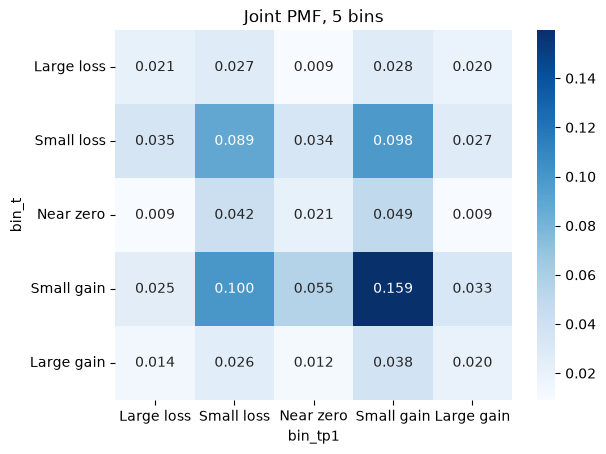

In [9]:
sns.heatmap(joint5.iloc[:-1, :-1], annot=True, fmt='.3f', cmap='Blues')
plt.title('Joint PMF, 5 bins')
plt.show()

**2B:** The most likely transitions are Small gain to Small gain (0.159), Small gain to Small loss (0.100), Small loss to Small gain (0.098), and Small loss to Small loss (0.089). These are the biggest simply because those states happen most often, so the conditional table is a better way to judge prediction.

In [10]:
cond5 = pd.crosstab(df['bin_t'], df['bin_tp1'], normalize='index')
cond5.round(3)

bin_tp1,Large loss,Small loss,Near zero,Small gain,Large gain
bin_t,,,,,
Large loss,0.203,0.259,0.086,0.265,0.186
Small loss,0.125,0.313,0.121,0.345,0.097
Near zero,0.071,0.321,0.160,0.377,0.071
Small gain,0.067,0.269,0.148,0.428,0.088
Large gain,0.127,0.235,0.107,0.348,0.183


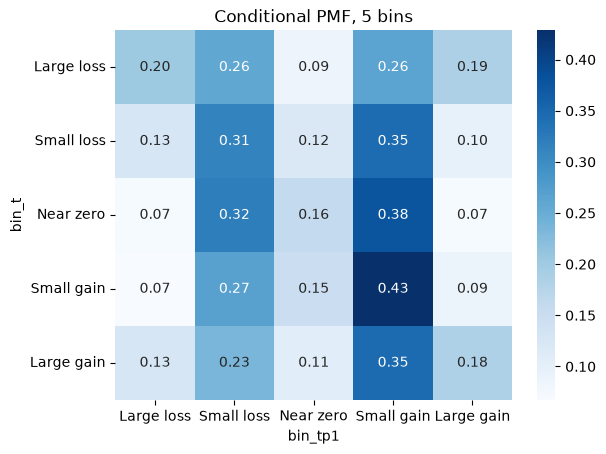

In [11]:
sns.heatmap(cond5, annot=True, fmt='.2f', cmap='Blues')
plt.title('Conditional PMF, 5 bins')
plt.show()

**2C:** For every current state, the two most likely next states are Small gain and Small loss. After a Large loss: Small gain (0.265), then Small loss (0.259). After a Small loss: Small gain (0.345), then Small loss (0.313). After Near zero: Small gain (0.377), then Small loss (0.321). After a Small gain: Small gain (0.428), then Small loss (0.269). After a Large gain: Small gain (0.348), then Small loss (0.235).

**2D:** No row is close to 0.2 for every state. The row closest to even is Large loss, and the least even is Small gain (0.43 chance of another Small gain). One pattern is that big moves tend to follow big moves: Large loss is followed by another Large loss 20% of the time and Large gain by another Large gain 18% of the time, versus roughly 7% to 13% after other states. Overall the next state is hard to predict, since the best guess is right only about 35% to 43% of the time.

In [12]:
cond_stats = df.groupby('bin_t', observed=False)['r_tp1'].describe()
cond_stats.round(3)

,count,mean,std,min,25%,50%,75%,max
bin_t,,,,,,,,
Large loss,2759.0,-0.038,1.721,-17.41,-0.79,-0.01,0.72,11.22
Small loss,7452.0,-0.044,1.010,-11.23,-0.53,0.01,0.45,11.36
Near zero,3441.0,0.015,0.826,-8.19,-0.35,0.03,0.42,5.49
Small gain,9784.0,0.107,0.832,-8.25,-0.25,0.12,0.50,8.67
Large gain,2859.0,0.163,1.384,-12.00,-0.37,0.15,0.73,15.67


**2E:** The expected return tomorrow is small and goes up as today's category goes up. After a Large loss it is -0.038%, after a Small loss -0.044%, after Near zero +0.015%, after a Small gain +0.107%, and after a Large gain +0.163%. These differences are tiny compared with how much returns bounce around, so they do not help much.

**2F:** Tomorrow's range is widest after the big days. After a Large loss it runs from -17.41 to 11.22, and after a Large gain from -12.00 to 15.67. After Near zero it is only -8.19 to 5.49, and after a Small gain it is -8.25 to 8.67.

**2G:** The standard deviation of tomorrow's return is highest after a Large loss (1.72), then after a Large gain (1.38), then after a Small loss (1.01). It is lowest after Near zero (0.83) and after a Small gain (0.83).

**2H:** Big moves, up or down, are followed by more volatile days, and quiet days are followed by quiet days. This is called volatility clustering. It is stronger after losses than after gains. So we cannot tell much about the direction of tomorrow's move, but we can tell something about how big it will be.

***

### 3. Scaling up

The choice of five bins was arbitrary. For more realistic or complex models, we'd want to flexibly choose the number of bins. Instead of the five bins from above, we'll break the data into 21 equally spaced bins based on quantile; the qualitative results hold up for 11 or 71 or 101, but 21 is interpretable and easier to manage.

- Use `pd.qcut` to assign the data into 21 bins, and add that variable to the dataframe as `df[y_t]`. Use `.shift(-1)` to create `df[y_tp1]`. 
- Compute the joint PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21**2 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random behavior.
- Compute the conditional PMF. Plot it as a heatmap. Do you see any obvious patterns? Explain. Try subtracting 1/21 from the PMF before plotting it, to normalize away the uniform PMF, and see systematic deviations from uniformly random transitions.
- For each bin, compute the next day's minimum, mean, and maximum values. Plots these as lines on a graph against the bins. Do you see any obvious patterns? Explain. 
- For each bin, compute the next day's standard deviation, and plot it as a line graph against the bins. Do you see any obvious patterns? Explain. 
- How easy is it to predict the market?

In [13]:
n = 21
df['y_t'] = pd.qcut(df['market_return_pct'], n, labels=False)
df['y_tp1'] = df['y_t'].shift(-1)
df['r_tp1'] = df['market_return_pct'].shift(-1)
pairs21 = df.dropna(subset=['y_tp1']).astype({'y_tp1': int})
pairs21['y_t'].value_counts().sort_index().describe()  # bins hold roughly equal numbers of days

count      21.000000
mean     1252.142857
std        46.961991
min      1193.000000
25%      1223.000000
50%      1238.000000
75%      1282.000000
max      1371.000000
Name: count, dtype: float64

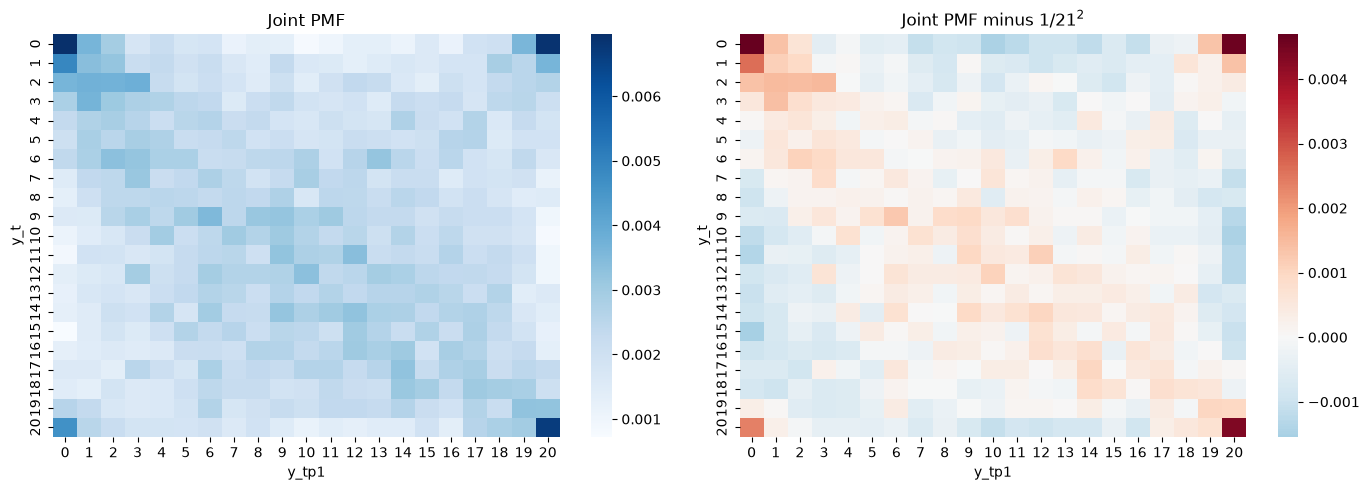

In [14]:
joint21 = pd.crosstab(pairs21['y_t'], pairs21['y_tp1'], normalize=True)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(joint21, cmap='Blues', ax=axes[0]).set(title='Joint PMF')
sns.heatmap(joint21 - 1/n**2, cmap='RdBu_r', center=0, ax=axes[1]).set(title='Joint PMF minus 1/21$^2$')
plt.tight_layout()
plt.show()

**3A:** The raw joint table is almost flat (every cell is close to 1/441) because each bin holds about the same number of days. After subtracting 1/21 squared, all four corners are above average. That means very bad days and very good days tend to be followed by very bad or very good days. Middle days are slightly less likely to be followed by extreme days. Big moves tend to cluster together.

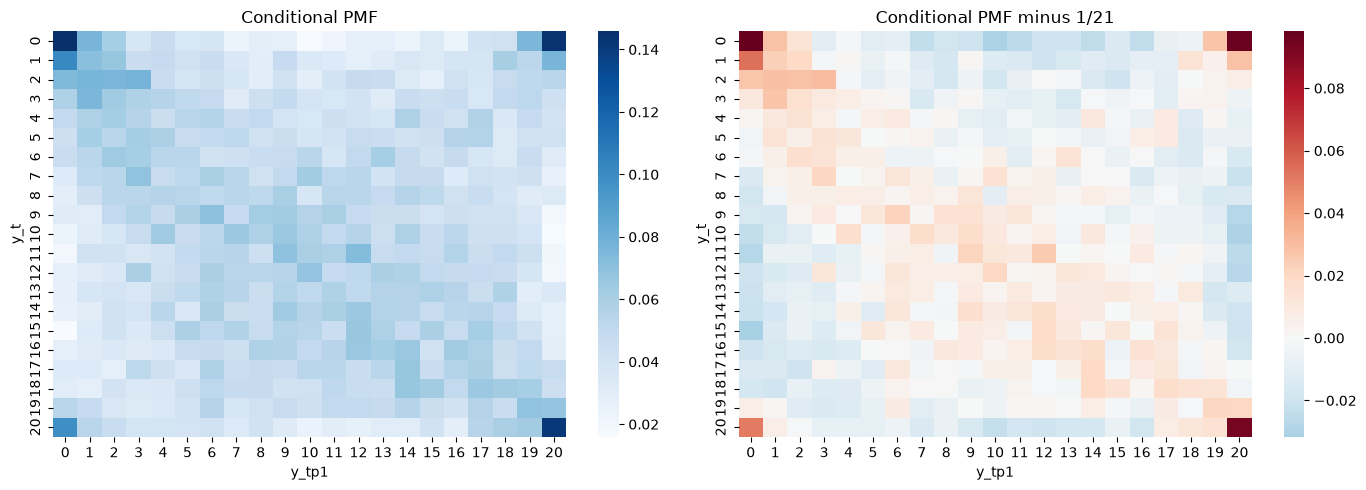

In [15]:
cond21 = pd.crosstab(pairs21['y_t'], pairs21['y_tp1'], normalize='index')
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(cond21, cmap='Blues', ax=axes[0]).set(title='Conditional PMF')
sns.heatmap(cond21 - 1/n, cmap='RdBu_r', center=0, ax=axes[1]).set(title='Conditional PMF minus 1/21')
plt.tight_layout()
plt.show()

**3B:** Before subtracting anything, all the rows look alike. After subtracting 1/21, the rows for the worst and best days put extra probability (about 0.05 to 0.10) on the worst and best days for tomorrow. The middle rows put a bit less on the extremes and a bit more on the middle. Most differences are small (within about 0.03), so today mostly changes how likely big moves are, not where the middle is.

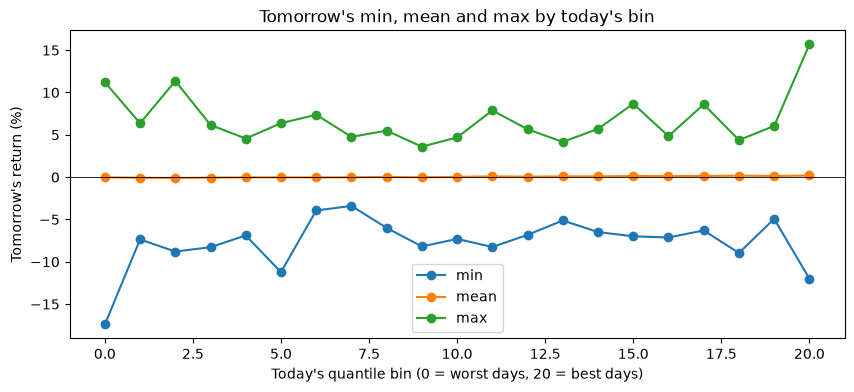

In [16]:
by_bin = pairs21.groupby('y_t')['r_tp1'].agg(['min', 'mean', 'max', 'std'])
fig, ax = plt.subplots(figsize=(10, 4))
by_bin[['min', 'mean', 'max']].plot(ax=ax, marker='o')
ax.axhline(0, color='black', linewidth=0.6)
ax.set(xlabel="Today's quantile bin (0 = worst days, 20 = best days)", ylabel="Tomorrow's return (%)",
       title="Tomorrow's min, mean and max by today's bin")
plt.show()

**3C:** The mean line is small (between about -0.10 and +0.20) and rises a little from the worst-day bins to the best-day bins. The min and max lines are jumpy because each is a single extreme day, but they are farthest apart at the two ends (bin 0 and bin 20) and closer together in the middle.

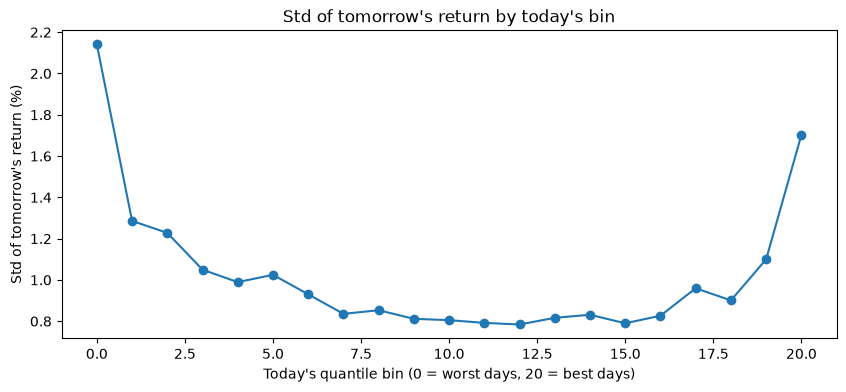

In [17]:
fig, ax = plt.subplots(figsize=(10, 4))
by_bin['std'].plot(ax=ax, marker='o')
ax.set(xlabel="Today's quantile bin (0 = worst days, 20 = best days)", ylabel="Std of tomorrow's return (%)",
       title="Std of tomorrow's return by today's bin")
plt.show()

**3D:** The standard deviation looks like a U. It is about 2.14 after the worst days, drops to about 0.78 in the middle bins, and rises to about 1.70 after the best days. The left side is higher, so big losses are followed by more volatility than big gains. This is the clearest pattern in the data.

**3E:** The market is hard to predict. The conditional tables are only a few points away from even, the average return tomorrow changes by only a few tenths of a percent, and the best Up/Down guess is right about 58% of the time. What we can predict a little is the size of tomorrow's move, since big days tend to be followed by big days. These results only use today's category and only describe this data.